# ML Regression Model Variants

This notebook compares three regression families on the same prepared Vulkan feature matrix: scikit-learn baselines, a PyTorch dense regressor, and a TensorFlow Keras dense regressor.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import display

from src.ml_model_utils import (
    model_runs_frame,
    reduce_feature_set,
    regression_target,
    run_sklearn_regression_models,
    run_tensorflow_regressor,
    run_torch_regressor,
)
from src.vulkan_math_data import feature_matrix, load_ml_dataset

2026-06-02 17:38:48.334965: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-02 17:38:48.733535: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-02 17:38:48.922628: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-02 17:38:48.924152: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-02 17:38:49.202686: I tensorflow/core/platform/cpu_feature_gua

In [2]:
ml_frame, diagnostics = load_ml_dataset()
X, _ = feature_matrix(ml_frame)
X = reduce_feature_set(X, max_features=16)
y, target_name = regression_target(ml_frame)
print("Target used:", target_name)
print("Rows available:", len(X))
print("Benchmark target rows:", diagnostics["benchmark_target_rows"])
display(
    ml_frame[
        [
            "report_id",
            "normalized_gpu_name",
            "target__benchmark",
            "target__surrogate_capability_score",
        ]
    ]
)

Target used: target__surrogate_capability_score
Rows available: 2
Benchmark target rows: 1


,report_id,normalized_gpu_name,target__benchmark,target__surrogate_capability_score
0,49077,rtx 4070 ti,101.0,425.0
1,49118,ryzen 9 7900x 12 core processor,NaN,368.5


In [3]:
sklearn_runs = run_sklearn_regression_models(X, y)
torch_run = run_torch_regressor(X, y, epochs=50)
tensorflow_run = run_tensorflow_regressor(X, y, epochs=50)
all_runs = sklearn_runs + [torch_run, tensorflow_run]
display(model_runs_frame(all_runs))

,framework,model,mae,r2
0,scikit-learn,ridge,0.856061,0.999082
1,scikit-learn,random_forest,12.995000,0.698400
2,scikit-learn,gradient_boosting,0.167255,0.999965
3,PyTorch,dense_regressor,371.296633,-172.618538
4,TensorFlow,keras_dense_regressor,351.777754,-155.860544


In [4]:
prediction_frame = ml_frame[["report_id", "normalized_gpu_name"]].copy()
prediction_frame["target"] = y.to_numpy()
for run in all_runs:
    prediction_frame[f"{run.framework}::{run.name}"] = run.predictions
display(prediction_frame)

,report_id,normalized_gpu_name,target,scikit-learn::ridge,scikit-learn::random_forest,scikit-learn::gradient_boosting,PyTorch::dense_regressor,TensorFlow::keras_dense_regressor
0,49077,rtx 4070 ti,425.0,424.143939,403.53,424.832745,27.297777,35.315392
1,49118,ryzen 9 7900x 12 core processor,368.5,369.356061,373.02,368.667255,23.608957,54.629101


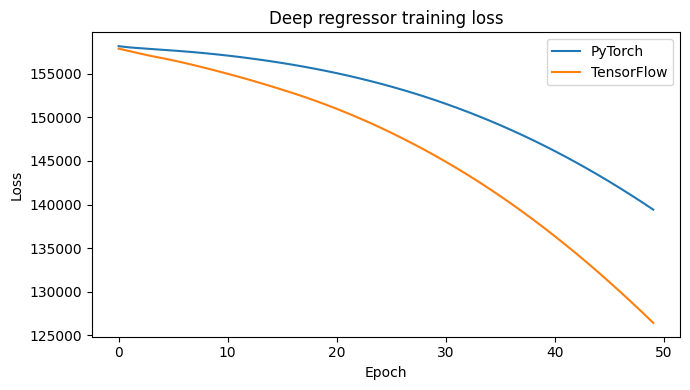

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(torch_run.details["loss_history"], label="PyTorch")
plt.plot(tensorflow_run.details["loss_history"], label="TensorFlow")
plt.title("Deep regressor training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()